## Ćwiczenie 7: Zadanie Samodzielne 

Twoim zadaniem jest stworzenie pełnego procesu segmentacyjnego dla pojedynczego przekroju z bazy danych z wykorzystaniem progowania Otsu i operacji morfologicznych. Na koniec oblicz faktyczne fizyczne pole powierzchni wyizolowanej struktury.

### Krok 1: Wczytanie i przygotowanie sztucznego zestawu danych 
Aby ułatwić zadanie bez konieczności pobierania plików .dcm, użyjemy wbudowany obraz oraz zasymulujemy odczyt atrybutu `PixelSpacing`.

C:\ProgramData\anaconda3\Lib\site-packages\paramiko\pkey.py:82: CryptographyDeprecationWarning: TripleDES has been moved to cryptography.hazmat.decrepit.ciphers.algorithms.TripleDES and will be removed from this module in 48.0.0.
  "cipher": algorithms.TripleDES,
C:\ProgramData\anaconda3\Lib\site-packages\paramiko\transport.py:219: CryptographyDeprecationWarning: Blowfish has been moved to cryptography.hazmat.decrepit.ciphers.algorithms.Blowfish and will be removed from this module in 45.0.0.
  "class": algorithms.Blowfish,
C:\ProgramData\anaconda3\Lib\site-packages\paramiko\transport.py:243: CryptographyDeprecationWarning: TripleDES has been moved to cryptography.hazmat.decrepit.ciphers.algorithms.TripleDES and will be removed from this module in 48.0.0.
  "class": algorithms.TripleDES,


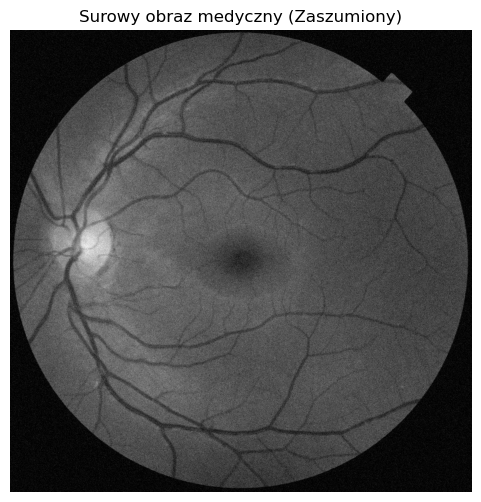

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from skimage import data, filters, morphology, util
from scipy import ndimage

# --- Symulacja środowiska klinicznego ---
# 1. Pobieramy wbudowany obraz siatkówki oka jako nasz "przypadek medyczny"
retina = data.retina()
image_medical = retina[:, :, 1] # Bierzemy tylko kanał zielony dla dużego kontrastu naczyń
image_medical = util.random_noise(image_medical, mode='gaussian', var=0.005) # Dodajemy szum sprzętowy

# 2. Symulujemy odczyt z nagłówka DICOM (tag 0028, 0030)
dicom_pixel_spacing_x = 0.08  # mm / pixel
dicom_pixel_spacing_y = 0.08  # mm / pixel

plt.figure(figsize=(6,6))
plt.imshow(image_medical, cmap='gray')
plt.title('Surowy obraz medyczny (Zaszumiony)')
plt.axis('off')
plt.show()

### Krok 2: Binaryzacja Otsu

**Twoje zadanie:**
1. Zastosuj wygładzanie obrazu filtrem Gaussa (`filters.gaussian`), aby nieco zredukować szum sprzętowy.
2. Znajdź optymalny próg jasności za pomocą metody Otsu (`filters.threshold_otsu`).
3. Utwórz surową maskę binarną. **Uwaga:** Interesują nas ciemne obszary (naczynia)! Upewnij się, że znak nierówności wybierze piksele *ciemniejsze* od progu.

In [8]:
# TUTAJ WPISZ SWÓJ KOD
# ...

# Do weryfikacji wizualnej (odkomentuj po napisaniu kodu):
# plt.imshow(surowa_maska, cmap='gray')
# plt.show()

### Krok 3: Naprawa morfologiczna

Prawdopodobnie Twoja maska zawiera mnóstwo białego szumu (pojedynczych pikseli w tle). 

**Twoje zadanie:**
Zastosuj operację **Otwarcia** (Opening), aby usunąć te artefakty, pozostawiając tylko główną sieć narządów. Dobierz odpowiedni rozmiar elementu strukturalnego (`morphology.disk(r)`), tak aby szum zniknął, ale główne odgałęzienia nie zostały całkowicie wymazane.

In [11]:
# TUTAJ WPISZ SWÓJ KOD
# ...

# Do weryfikacji wizualnej:
# plt.imshow(czysta_maska, cmap='gray')
# plt.show()

### Krok 4: Analityka i Fizyczne Pole Powierzchni (Kluczowy krok dla DICOM)

Radiolog nie wie, co to są piksele. Potrzebuje wyniku w milimetrach kwadratowych.

**Twoje zadanie:**
1. Oblicz ile pojedynczych pikseli składa się na Twoją `czysta_maska`.
2. Wykorzystaj zmienne `dicom_pixel_spacing_x` oraz `dicom_pixel_spacing_y` (podane w Kroku 1), aby wyliczyć pole powierzchni jednego piksela w $mm^2$.
3. Pomnóż wynik i wypisz końcowe fizyczne pole powierzchni sieci naczyniowej.
4. (Dla ambitnych) Stwórz kolorowy obrys maski używając `^` (XOR) i nałóż go na obraz oryginalny.

In [14]:
# TUTAJ WPISZ SWÓJ KOD
# ...
